# 01 — Counting bigrams: a first language model without training

**Chapter 1** · suggested time: 30 min · CPU only · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_1/01_counting_bigrams.ipynb)

![Chapter roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_1/figures/00_roadmap.png)

> **The chapter's common thread:** a bigram model can be obtained in two ways. We can **count** the transitions in the data and turn them into a probability table. We can also **learn** a weight matrix by gradient descent. Both paths lead to almost the same table (notebook 06).

**By the end of this notebook you will be able to:**
1. count the transitions between characters in a matrix `N` of shape `(27, 27)`;
2. turn these counts into conditional probabilities `P(next | current)`;
3. draw a random character with `torch.multinomial` and generate names;
4. explain why these names are plausible locally but not globally.

**Convention:** the symbol `.` marks the **start** and the **end** of a name. We only predict the **next character**, given the current character.

## 0. The challenge: inventing new names

A **language model** assigns a probability to the **next symbol**, given a context. Here, the context is reduced to **a single character**. This is a **bigram model** (*bi* = two: the current character and the next one).

The idea is not new: in 1948, Claude Shannon was already producing "fake English" by drawing each letter according to the previous letter. Today's large language models do the same thing, with a context of several thousand *tokens* instead of one character.

We use `names.txt`, about 32,000 English names (the dataset from Andrej Karpathy's *makemore* project). The small `bigram.py` module reads the file next to the notebook, or in the repository's `corpus/` folder, and downloads it otherwise.

In [1]:
# On Google Colab: fetch the course repository (corpus + shared modules such as bigram.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("bigram.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_1

In [2]:
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import bigram
from bigram import SEED, plot_char_matrix

words = bigram.load_names()
print(f"{len(words):,} names")
print("First ten:", words[:10])
lengths = [len(w) for w in words]
print(f"Length: min {min(lengths)}, max {max(lengths)}, mean {sum(lengths)/len(lengths):.1f}")

32,033 names
First ten: ['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn']
Length: min 2, max 15, mean 6.1


**Opening question:** how many "prediction exercises" does a 4-letter name contain? Answer: **5**. For `emma`, we predict `e` after the start, then `m` after `e`, `m` after `m`, `a` after `m`, and finally the end after `a`.

## 1. A vocabulary of 27 symbols

A computer handles **numbers**, not letters. So we associate an integer with each symbol:

- `stoi` (*string to integer*): character → index;
- `itos` (*integer to string*): index → character.

The `.` gets index 0 and the letters `a` to `z` get indices 1 to 26. These numbers are mere **labels**: `m = 13` does not mean that `m` is "bigger" than `a`. We will come back to this in notebook 03.

In [3]:
chars, stoi, itos = bigram.build_vocabulary(words)
print("Letters present:", "".join(chars))
print("stoi:", {c: stoi[c] for c in ".abcmz"})
print("itos:", {i: itos[i] for i in [0, 1, 2, 3, 13, 26]})

Letters present: abcdefghijklmnopqrstuvwxyz
stoi: {'.': 0, 'a': 1, 'b': 2, 'c': 3, 'm': 13, 'z': 26}
itos: {0: '.', 1: 'a', 2: 'b', 3: 'c', 13: 'm', 26: 'z'}


## 2. The count table `N`

![Counting the bigrams of emma](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_1/figures/01_counting_emma.png)

We want to answer the question **"given the current character, which one comes next?"**. There are 27 possible current characters and, for each, 27 possible next ones. Hence a table of **27 rows × 27 columns**:

- **row `i`**: the current character;
- **column `j`**: the next character;
- **cell `N[i, j]`**: the number of times `j` followed `i` in the whole corpus.

`zip(sequence, sequence[1:])` lines up each character with the one that follows it. For each pair, we add 1 to the right cell.

**What to read in the code:** `N[stoi['a'], stoi['m']]` is a **number of observations**, not a probability yet.

In [4]:
N = torch.zeros((27, 27), dtype=torch.int32)

for w in words:
    sequence = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(sequence, sequence[1:]):
        N[stoi[ch1], stoi[ch2]] += 1

print("Shape of N:", tuple(N.shape))
print("Transitions counted:", N.sum().item())
print("N['a', 'm'] =", N[stoi['a'], stoi['m']].item(), "  (\"m\" right after \"a\")")
print("N['m', 'a'] =", N[stoi['m'], stoi['a']].item(), "  (\"a\" right after \"m\")")

Shape of N: (27, 27)
Transitions counted: 228146
N['a', 'm'] = 1634   ("m" right after "a")
N['m', 'a'] = 2590   ("a" right after "m")


**Quick question:** does `N[stoi['a'], stoi['m']]` mean "a after m" or "m after a"? Row = current, column = next: it is **"m after a"**. The two counts above are different: the table is **not symmetric**.

**Quick check:** how many transitions in total? Each name of length `L` gives `L + 1` transitions. So the sum of `N` equals `number of letters + number of names`.

Check OK: 196113 letters + 32033 names = 228146


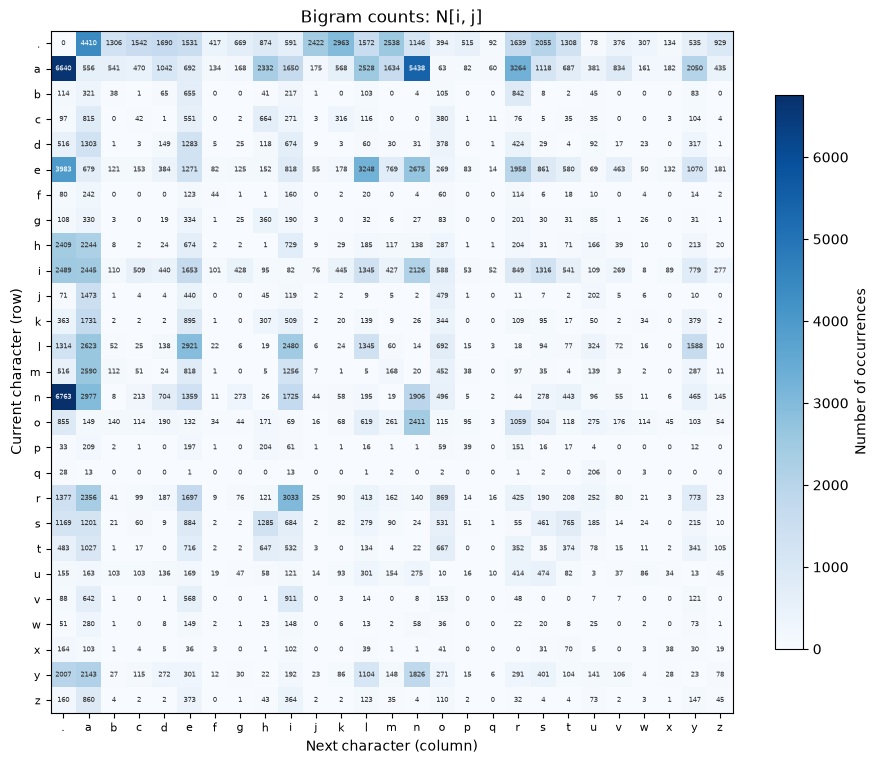

In [5]:
assert N.sum().item() == sum(lengths) + len(words)
print("Check OK:", sum(lengths), "letters +", len(words), "names =", N.sum().item())

plot_char_matrix(N, itos, title="Bigram counts: N[i, j]",
                 cbar_label="Number of occurrences", annotate=True, figsize=(11, 9))
plt.show()

**Reading the map:** pick a row (current character), then a column (next character). The darker the cell, the more frequent the transition.

- The **`.` row** gives the first letters of names.
- The **`.` column** shows the letters that often end a name (`n`, `a`, `e`, `y`…).
- Many cells are almost white: some transitions are rare, and a few **never** appear (we will see in notebook 02 that this is a problem).

Here are the most frequent transitions:

In [6]:
values, positions = N.flatten().topk(10)
for v, pos in zip(values, positions):
    i, j = divmod(pos.item(), 27)
    print(f"  {itos[i]} → {itos[j]}: {v.item():5d}")
print("Zero cells:", (N == 0).sum().item(), "out of 729")

  n → .:  6763
  a → .:  6640
  a → n:  5438
  . → a:  4410
  e → .:  3983
  a → r:  3264
  e → l:  3248
  r → i:  3033
  n → a:  2977
  . → k:  2963
Zero cells: 102 out of 729


## 3. From counts to probabilities

A **probability distribution** is a set of **non-negative** values that sum to **1**. For a current character `i`, we divide each cell of the row by the row total:

$$
P(j\mid i)=\frac{N_{ij}}{\sum_k N_{ik}}.
$$

**Why divide by the row sum?** Imagine that the row of `a` contains only three outcomes: `m: 30`, `n: 10`, `.: 10`. Out of **50** occurrences of `a` as the current character, `m` comes next 30 times, hence

$$
P(m\mid a) = \frac{30}{50} = 0.60.
$$

In other words: "among the times the current character is `a`, 60% are followed by `m`". We divide **row by row** because we condition on the current character: the distribution after `a` is not the one after `m`.

Let's start with the `.` row, which gives the **first letter** of a name.

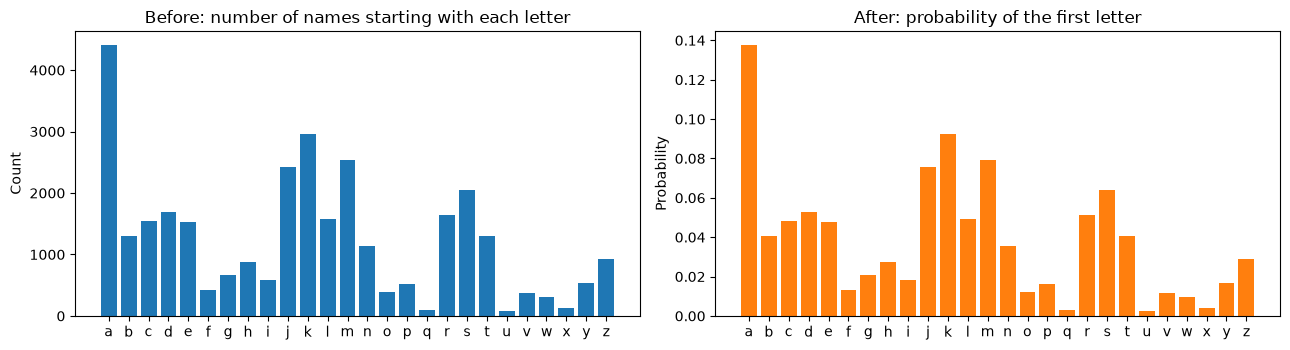

Row sum after normalization: 1.0


In [7]:
start_counts = N[0].float()
start_probs = start_counts / start_counts.sum()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(chars, start_counts[1:].numpy())
ax[0].set_title("Before: number of names starting with each letter")
ax[0].set_ylabel("Count")
ax[1].bar(chars, start_probs[1:].numpy(), color="tab:orange")
ax[1].set_title("After: probability of the first letter")
ax[1].set_ylabel("Probability")
plt.tight_layout(); plt.show()
print("Row sum after normalization:", round(start_probs.sum().item(), 6))

The two plots have **exactly the same shape**: only the vertical scale changes. Normalizing does not change the preferences, it makes them comparable from one row to another.

### Normalizing all rows at once… and the broadcasting trap

We want to divide each row of `N` by **its own** sum. `N.sum(dim=1, keepdim=True)` gives a column vector of shape `(27, 1)`. PyTorch "copies" it across the 27 columns: this is **broadcasting**.

**Classic trap:** without `keepdim=True`, the sum has shape `(27,)`. PyTorch then interprets it as a **row** `(1, 27)` and divides each **column** by the sum of a row. The code does not crash, but the result is wrong. Let's check.

In [8]:
row_sums = N.sum(dim=1, keepdim=True)
print("With keepdim=True:", tuple(row_sums.shape), " | without:", tuple(N.sum(dim=1).shape))

P_wrong = N.float() / N.sum(dim=1)                      # (27,27) / (27,)  -> divides the columns!
P = N.float() / N.sum(dim=1, keepdim=True)              # (27,27) / (27,1) -> divides the rows

print("Row sums, wrong version  :", P_wrong.sum(dim=1)[:5].round(decimals=3).tolist(), "…")
print("Row sums, correct version:", P.sum(dim=1)[:5].round(decimals=3).tolist(), "…")
assert torch.allclose(P.sum(dim=1), torch.ones(27))

With keepdim=True: (27, 1)  | without: (27,)
Row sums, wrong version  : [7.021999835968018, 4.414000034332275, 0.20100000500679016, 0.3720000088214874, 0.41499999165534973] …
Row sums, correct version: [1.0, 1.0, 1.0, 1.0, 1.0] …


> **Key takeaway:** when normalizing "by row", write `sum(dim=1, keepdim=True)`. Always check that a distribution sums to 1: it is a one-line test that saves hours of debugging.

## 4. Drawing the next character: `torch.multinomial`

A row of `P` says **how** probable each next character is. It does not say **which one** will be drawn. That is the job of `torch.multinomial`.

With three outcomes `p = [0.6, 0.3, 0.1]` (for `a`, `b`, `c`), we get **on average** 60% `a`, 30% `b` and 10% `c`. A single draw may very well give `c`: that is not a mistake.

- `num_samples=1`: we want **one** next character;
- `replacement=True`: allows the same index to come up again across multiple draws;
- `generator=g`: a generator with a fixed seed so that everyone gets the same draws;
- `.item()`: converts the tensor to a Python integer.

In [9]:
g = torch.Generator().manual_seed(SEED)
p = torch.tensor([0.6, 0.3, 0.1])

print("One draw:", torch.multinomial(p, num_samples=1, replacement=True, generator=g).item())
draws = torch.multinomial(p, num_samples=10_000, replacement=True, generator=g)
frequencies = torch.bincount(draws, minlength=3) / len(draws)
print("Frequencies over 10,000 draws:", frequencies.round(decimals=3).tolist(), " vs p =", p.tolist())

One draw: 0
Frequencies over 10,000 draws: [0.6019999980926514, 0.29600000381469727, 0.10199999809265137]  vs p = [0.6000000238418579, 0.30000001192092896, 0.10000000149011612]


**Do not confuse it with `argmax`.** `argmax` **always** picks the most probable outcome: generation becomes deterministic and repetitive. `multinomial` gives the other outcomes a chance, which produces variety.

### Generating names

1. start from `.` (index 0);
2. draw the next character from the row `P[ix]`;
3. this character becomes the new current character: start again with **its** row;
4. stop when we draw `.`.

In [10]:
def sample_names_from_table(P, n=8, seed=SEED, argmax=False):
    g = torch.Generator().manual_seed(seed)
    results = []
    for _ in range(n):
        out, ix = [], 0
        for _ in range(40):                       # safeguard: 40 characters at most
            if argmax:
                ix = P[ix].argmax().item()
            else:
                ix = torch.multinomial(P[ix], 1, replacement=True, generator=g).item()
            if ix == 0:
                break
            out.append(itos[ix])
        results.append("".join(out))
    return results

print("With multinomial:", sample_names_from_table(P, 10))
print("With argmax     :", sample_names_from_table(P, 3, argmax=True))

With multinomial: ['cexze', 'momasurailezitynn', 'konimittain', 'llayn', 'ka', 'da', 'staiyaubrtthrigotai', 'moliellavo', 'ke', 'teda']
With argmax     : ['a', 'a', 'a']


With `argmax`, all names are identical and reduced to `a`. After `.`, the most frequent letter is `a`. After `a`, the most frequent symbol is `.` (many names end in *a*). So the "most probable" path stops immediately.

### Is it better than chance?

Let's compare with a **uniform** model, which gives `1/27` to each character in every row. It has learned nothing from the corpus.

In [11]:
P_uniform = torch.ones(27, 27) / 27
print("Uniform model:", sample_names_from_table(P_uniform, 6))
print("Bigram model :", sample_names_from_table(P, 6))

name_set = set(words)
generated = sample_names_from_table(P, 1000, seed=0)
print(f"\nOut of 1000 generated names, {sum(g in name_set for g in generated)} already exist in names.txt")
print("Mean generated length:", round(sum(map(len, generated)) / 1000, 1), " | real:",
      round(sum(lengths) / len(lengths), 1))

Uniform model: ['cexzm', 'zoglkurkicqzktyhwmvmzimjttainrlkfukzkktd', 'a', 'sfcxvpubjtbhrmgotzx', 'iczixqctvujkwptedogkkjemkmmsidguenkbvgyn', 'ywftbspmhwcivgbvtahlvsu']
Bigram model : ['cexze', 'momasurailezitynn', 'konimittain', 'llayn', 'ka', 'da']



Out of 1000 generated names, 102 already exist in names.txt
Mean generated length: 6.3  | real: 6.1


**Discussion:**
- The uniform model produces very long, unpronounceable strings: it draws `.` only once in 27 times.
- The bigram has learned real things: which letters start and end a name, which letters follow each other. Its lengths are close to the real ones.
- But its names are often **incoherent as a whole**. It only knows **the last character**: it has no memory of the syllable or of the length already written.

## Summary

| Step | Code | What we get |
|---|---|---|
| Count | `N[stoi[ch1], stoi[ch2]] += 1` | 729 counters |
| Normalize | `P = N / N.sum(1, keepdim=True)` | 27 distributions, one per current character |
| Generate | `torch.multinomial(P[ix], 1)` in a loop | new names |

**The question that kicks off notebook 02:** the names "look" better than with the uniform model. But how do we **measure** that with a number? We need an objective score, and that will be the **loss**.

## References
- C. E. Shannon, [*A Mathematical Theory of Communication*](https://people.math.harvard.edu/~ctm/home/text/others/shannon/entropy/entropy.pdf), 1948, section 3: approximations of English by strings of letters.
- D. Jurafsky and J. H. Martin, [*Speech and Language Processing*](https://web.stanford.edu/~jurafsky/slp3/), chapter 3 "N-gram Language Models".
- Andrej Karpathy, [*The spelled-out intro to language modeling: building makemore*](https://www.youtube.com/watch?v=PaCmpygFfXo) (2022) and the [makemore](https://github.com/karpathy/makemore) repository, where `names.txt` and the spirit of this chapter come from.
- PyTorch documentation: [broadcasting](https://pytorch.org/docs/stable/notes/broadcasting.html), [`torch.multinomial`](https://pytorch.org/docs/stable/generated/torch.multinomial.html).